# DistilBERT threshold tuning

Load `best_model.safetensors` from `01_train.ipynb` and load the validation pairs directly from `val_pairs.csv`. These pairs come from the reviewed gold standard, `gs_pair_train_val.csv`. Sweep the match-probability threshold from `0.10` to `0.90` with `step=0.01` and choose the highest validation macro F1. Ties favor the threshold closest to `0.50`, then the smaller threshold.

Save the selected cutoff in `tuned_threshold.json`. Save `validation_probabilities.csv` and `threshold_history.csv`. Plot macro F1 against threshold, marking `0.50` and the selected cutoff. Reserve `gs_pair_test.csv` for `03_evaluate.ipynb`.

In [1]:
import os
import json
import time
from pathlib import Path

os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DistilBertConfig, DistilBertForSequenceClassification
from safetensors.torch import save_model, load_model
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data/5_golden_standard_pair').exists())
work_dir = project_root / 'notebooks/PLM_DistilBERT'
pretrained_dir = work_dir / 'pretrained'
data_dir = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f'Device: {device}')

Device: cpu


## Tokenization

- `make_dataset`: serialize the selected attributes of both medicines and convert each labeled pair into token sequences.

In [2]:
def make_dataset(frame, tokenizer, attributes, max_length):
    """Serialize and tokenize medicine pairs with their binary labels.

    Parameters
    ----------
    frame : pandas.DataFrame
        Pair attributes with numeric suffixes and reviewed match labels.
    tokenizer : PreTrainedTokenizerBase
        Locally loaded tokenizer.
    attributes : list[str]
        Fields included in each record; excludes IDs and review metadata.
    max_length : int
        Maximum total tokens per pair, including special tokens.

    Returns
    -------
    TensorDataset
        Input IDs, attention masks, and labels in input row order.
    """
    texts = []
    for suffix in ['1', '2']:
        records = []
        for _, row in frame.iterrows():
            fields = []
            for attribute in attributes:
                value = row.get(attribute + suffix)
                value = '' if pd.isna(value) else ' '.join(str(value).split())
                fields.append(f'[COL] {attribute} [VAL] {value}')
            records.append(' '.join(fields))
        texts.append(records)
    encoded = tokenizer(texts[0], texts[1], padding='max_length',
                        truncation=True, max_length=max_length, return_tensors='pt')
    labels = torch.tensor(frame['match'].to_numpy(), dtype=torch.long)
    return TensorDataset(encoded['input_ids'], encoded['attention_mask'], labels)

## Best checkpoint

Load `best_model.safetensors` using the existing model configuration in `pretrained/`.

In [3]:
# Reuse the training input settings
batch_size = 16
max_length = 128
attributes = ['brandName', 'activeSubstances', 'licenceHolder']

checkpoint_path = work_dir / 'best_model.safetensors'
tokenizer = AutoTokenizer.from_pretrained(pretrained_dir, local_files_only=True)
model_config = DistilBertConfig.from_pretrained(pretrained_dir, local_files_only=True, num_labels=2)
model = DistilBertForSequenceClassification(model_config)
load_model(model, str(checkpoint_path))
model.to(device)
print('Loaded best model checkpoint.')

Loaded best model checkpoint.


## Validation probabilities

Load the full reviewed pairs from `val_pairs.csv`. Collect `match_probability` once with dropout disabled through `model.eval()`.

In [4]:
# Load Validation Pairs
val_pairs = pd.read_csv(work_dir / 'val_pairs.csv')
val_dataset = make_dataset(val_pairs, tokenizer, attributes, max_length)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
# Collect Validation Match Probabilities
model.eval()
val_probabilities = []
with torch.inference_mode():
    for input_ids, attention_mask, _ in val_loader:
        output = model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device))
        val_probabilities.extend(output.logits.softmax(dim=-1)[:, 1].cpu().tolist())
val_probabilities = np.array(val_probabilities)
val_labels = val_pairs['match'].to_numpy()

validation_predictions = val_pairs[['id1', 'id2', 'source_pair', 'hard', 'match']].copy()
validation_predictions['match_probability'] = val_probabilities
validation_predictions.to_csv(work_dir / 'validation_probabilities.csv', index=False)
print(f'Collected probabilities for {len(val_pairs)} validation pairs.')

Collected probabilities for 595 validation pairs.


## Threshold search

Predict match when `match_probability >= threshold`. Select the highest validation `macro_f1` and save the chosen cutoff to `tuned_threshold.json`.

In [7]:
threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.901, 0.01), 2):
    threshold_rows.append({'threshold': float(threshold),
                           'macro_f1': f1_score(val_labels, val_probabilities >= threshold,
                                                labels=[0, 1], average='macro', zero_division=0)})
threshold_history = pd.DataFrame(threshold_rows)
best_score = threshold_history['macro_f1'].max()
tied = threshold_history[np.isclose(threshold_history['macro_f1'], best_score, atol=1e-12, rtol=0)].copy()
tied['distance_to_default'] = (tied['threshold'] - 0.50).abs().round(10)
selected = tied.sort_values(['distance_to_default', 'threshold']).iloc[0]
selected_threshold = float(selected['threshold'])
threshold_history.to_csv(work_dir / 'threshold_history.csv', index=False)
threshold_settings = {
    'threshold': selected_threshold, 'default_threshold': 0.50,
    'validation_macro_f1': float(selected['macro_f1']),
    'grid_start': 0.10, 'grid_end': 0.90, 'grid_step': 0.01,
    'selection_metric': 'validation_macro_f1',
    'tie_break': 'closest_to_0.50_then_smaller_threshold',
}
(work_dir / 'tuned_threshold.json').write_text(json.dumps(threshold_settings, indent=2), encoding='utf-8')
print(f'Selected threshold: {selected_threshold:.2f}; validation macro F1: {best_score:.4f}')

Selected threshold: 0.17; validation macro F1: 0.9387


## Tuning curve

Plot validation macro F1 from `threshold_history.csv`, marking the selected cutoff and the default cutoff of `0.50`.

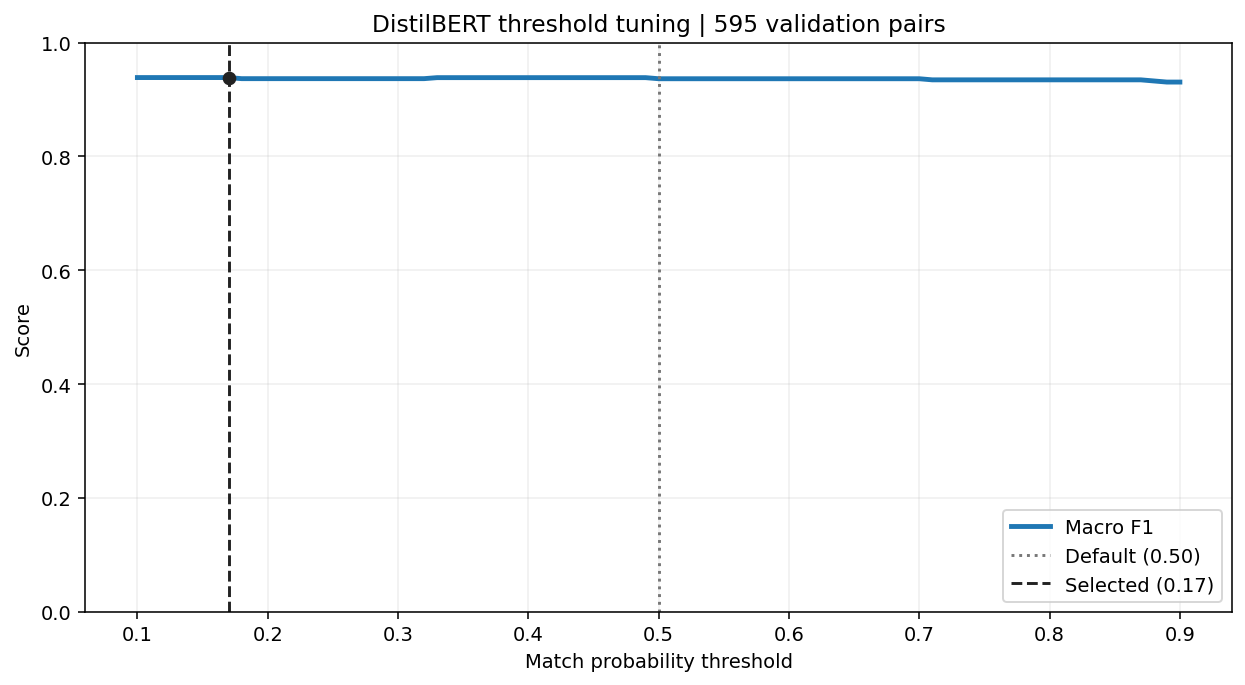

In [8]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=140)
ax.plot(threshold_history['threshold'], threshold_history['macro_f1'], label='Macro F1', linewidth=2.5)
ax.axvline(0.50, color='#777777', linestyle=':', label='Default (0.50)')
ax.axvline(selected_threshold, color='#222222', linestyle='--', label=f'Selected ({selected_threshold:.2f})')
ax.scatter([selected_threshold], [best_score], color='#222222', zorder=5)
ax.set(xlabel='Match probability threshold', ylabel='Score', ylim=(0, 1),
       title=f'DistilBERT threshold tuning | {len(val_pairs)} validation pairs')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(work_dir / 'threshold_tuning.png', dpi=300, bbox_inches='tight')
plt.show()